# Sentence Transformer Applications Demo

Practical applications of Sentence Transformers:

- text similarity with cosine similarity
- semantic search beyond keyword matching
- a retrieval-based FAQ chatbot
- text clustering by meaning
- text classification using embeddings as features
- recommendation systems based on description similarity
- paraphrase detection
- multilingual semantic search

The examples use small in-memory datasets so the ideas remain visible. The first run may take a few minutes if the multilingual model must be downloaded.


## 0. Setup

We use `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` for every example. It maps sentences from many languages into the same 384-dimensional semantic vector space.

Normalized embeddings let us compute cosine similarity with a simple dot product:

$$
\operatorname{cosine}(a,b)=\frac{a \cdot b}{\|a\|\|b\|}
$$


In [ ]:
!pip install sentence-transformers

In [ ]:
import os
import warnings

# Reduce TensorFlow logging so the notebook output stays focused on the demo results.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# Disable tokenizer parallel warnings when the notebook runs in a Jupyter kernel.
os.environ["TOKENIZERS_PARALLELISM"] = "false"
# Hide library FutureWarnings so the presentation stays cleaner.
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# Choose a multilingual model for both English text and other languages.
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

# Load the multilingual model; the first run may take longer if the model is not yet cached.
model = SentenceTransformer(MODEL_NAME)


def embed_texts(texts):
    """Encode one string or a list of strings into normalized embeddings.

    Parameters:
        texts: A string or a list of strings.

    Returns:
        A NumPy vector for one string or a matrix for a list of strings.
    """
    # Record whether the input is a string or a list so the function returns the correct type at the end.
    single_text = isinstance(texts, str)
    # The model always expects a list, so a single string must be wrapped in a one-item list.
    if single_text:
        texts = [texts]

    # normalize_embeddings=True makes the dot product equivalent to cosine similarity.
    embeddings = model.encode(
        texts,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=False,
    )
    # If the input starts as a single string, return one vector; if it is a list, return a matrix.
    return embeddings[0] if single_text else embeddings


def cosine_score(text_a, text_b):
    """Compute cosine similarity between two texts.

    Parameters:
        text_a: First text.
        text_b: Second text.

    Returns:
        Cosine similarity as a float.
    """
    # Encode the first text into a normalized semantic vector.
    vector_a = embed_texts(text_a)
    # Encode the second text in the same embedding space.
    vector_b = embed_texts(text_b)

    # The two vectors are normalized, so only the dot product is needed.
    return float(vector_a @ vector_b)


def rank_by_similarity(query, items, item_embeddings, top_k=5):
    """Rank indexed items by semantic similarity to a query.

    Parameters:
        query: Query text.
        items: Item dictionaries containing display fields.
        item_embeddings: Precomputed normalized item embeddings.
        top_k: Number of results to return.

    Returns:
        A list of dictionaries with rank, score, and item fields.
    """
    # Encode the query once before comparing it with the full index.
    query_embedding = embed_texts(query)

    # Compare the query with all items in a single matrix multiplication.
    scores = item_embeddings @ query_embedding
    # Sort the indices by descending score and keep only the best top_k results.
    ranked_indices = np.argsort(scores)[::-1][:top_k]
    # Create a list to store the ranked results along with the original metadata.
    results = []
    # Iterate through the ranked indices and assign them an ordinal starting at 1.
    for rank, index in enumerate(ranked_indices, start=1):
        # Combine rank, score, and the item fields into a result dictionary.
        results.append({"rank": rank, "score": float(scores[index]), **items[int(index)]})
    # Return the sorted list so downstream applications can reuse it.
    return results


print("Model loaded:", MODEL_NAME)
print("Embedding dimension:", model.get_sentence_embedding_dimension())

## 1. Text Similarity

Sentence embeddings represent meaning rather than exact word overlap. Cosine similarity can therefore compare:

- two sentences
- two paragraphs
- two whole documents

Scores close to `1` indicate similar directions in the embedding space. The useful decision threshold depends on the model, language, and task.


In [ ]:
# Prepare sentence pairs with near-duplicate and unrelated relations to compare them.
sentence_pairs = [
    (
        "A student is learning machine learning.",
        "A learner is studying artificial intelligence.",
        "related",
    ),
    (
        "The university library closes at nine o'clock.",
        "The campus book center is open until 9 PM.",
        "related",
    ),
    (
        "The football team won the championship.",
        "The database server needs more memory.",
        "unrelated",
    ),
    (
        "I cannot sign in to my account.",
        "I forgot my password and cannot log in.",
        "related",
    ),
]

# Create a list that stores similarity scores and expected labels for each pair.
rows = []
# Iterate through each sentence pair in the illustrative dataset.
for text_a, text_b, expected_relation in sentence_pairs:
    # Each sentence pair is encoded separately and compared using cosine similarity.
    # Save the original sentence, expected relation, and cosine similarity in one result row.
    rows.append(
        {
            "text A": text_a,
            "text B": text_b,
            "expected": expected_relation,
            "cosine similarity": round(cosine_score(text_a, text_b), 3),
        }
    )

# Convert the list of dictionaries into a table for easier score comparison.
pd.DataFrame(rows)

,text A,text B,expected,cosine similarity
0,A student is learning machine learning.,A learner is studying artificial intelligence.,related,0.769
1,The university library closes at nine o'clock.,The campus book center is open until 9 PM.,related,0.597
2,The football team won the championship.,The database server needs more memory.,unrelated,0.102
3,I cannot sign in to my account.,I forgot my password and cannot log in.,related,0.736


In [ ]:
# Create four documents from different topics to build a similarity matrix.
documents = {
    "AI course": (
        "This course introduces machine learning, neural networks, and intelligent systems. "
        "Students build models that learn from data."
    ),
    "Data science course": (
        "This course teaches data analysis, predictive modeling, and visualization. "
        "Students use statistical and machine learning tools."
    ),
    "Marketing course": (
        "This course covers customer behavior, branding, digital campaigns, and market strategy. "
        "Students design communication plans for products."
    ),
    "Sports report": (
        "The basketball team trained for the final tournament. "
        "Players practiced defense and shooting every afternoon."
    ),
}

# Encode the full document set once to create a pairwise similarity matrix.
document_embeddings = embed_texts(list(documents.values()))
# Multiply the embedding matrix by its transpose to compute similarity for every document pair.
document_similarity = document_embeddings @ document_embeddings.T

# Put the similarity matrix into a DataFrame with row and column labels as document names.
pd.DataFrame(
    np.round(document_similarity, 3),
    index=documents.keys(),
    columns=documents.keys(),
)

,AI course,Data science course,Marketing course,Sports report
AI course,1.000,0.839,0.535,0.084
Data science course,0.839,1.000,0.558,0.137
Marketing course,0.535,0.558,1.000,0.062
Sports report,0.084,0.137,0.062,1.000


## 2. Semantic Search

Keyword search looks for shared words. Semantic search retrieves documents that express the same idea, even when the query uses different vocabulary.

The workflow is:

1. encode the document collection once
2. encode a user query
3. compute cosine similarity to every document
4. return the highest-scoring documents


In [ ]:
# Define a small knowledge base: each document has an ID, title, and content.
knowledge_base = [
    {
        "id": "KB-101",
        "title": "Resetting an account password",
        "text": "Use the account security page to create a new password after verifying your email address.",
    },
    {
        "id": "KB-102",
        "title": "Paying university fees",
        "text": "Tuition invoices can be paid online by card or bank transfer before the payment deadline.",
    },
    {
        "id": "KB-103",
        "title": "Borrowing library materials",
        "text": "Students can check out books and journals at the library desk with a valid student ID.",
    },
    {
        "id": "KB-104",
        "title": "Registering for classes",
        "text": "Course enrollment is available through the academic portal during the registration period.",
    },
    {
        "id": "KB-105",
        "title": "Joining student clubs",
        "text": "Contact student affairs or attend club day to join sports, music, and volunteer organizations.",
    },
    {
        "id": "KB-106",
        "title": "Requesting an academic transcript",
        "text": "Official transcripts can be ordered through the registrar and delivered electronically.",
    },
]

# The embedding index is precomputed and can be reused for many queries.
knowledge_embeddings = embed_texts([item["title"] + ". " + item["text"] for item in knowledge_base])


def semantic_search(query, top_k=3):
    """Search the knowledge base by meaning.

    Parameters:
        query: Natural-language search query.
        top_k: Number of documents to return.

    Returns:
        A DataFrame containing ranked search results.
    """
    # Call the shared ranking function to find the documents most semantically similar to the query.
    results = rank_by_similarity(query, knowledge_base, knowledge_embeddings, top_k=top_k)
    # Keep only the needed columns and return them as a search result table.
    return pd.DataFrame(results)[["rank", "score", "id", "title", "text"]]


# Run a query without the exact keyword "reset password" to illustrate semantic search.
semantic_search("I forgot my login credentials and need access again", top_k=3)

,rank,score,id,title,text
0,1,0.553323,KB-101,Resetting an account password,Use the account security page to create a new ...
1,2,0.167264,KB-104,Registering for classes,Course enrollment is available through the aca...
2,3,0.159311,KB-105,Joining student clubs,Contact student affairs or attend club day to ...


In [ ]:
# Prepare several natural phrasings for different search intents.
search_queries = [
    "How can I order an official academic transcript of my grades?",
    "I want to become a member of the university basketball group.",
    "How can I settle my semester bill?",
]

# Run each query against the same precomputed embedding index.
for query in search_queries:
    print("=" * 90)
    print("Query:", query)
    # Display the two most relevant documents for the current query.
    display(semantic_search(query, top_k=2))

Query: How can I order an official academic transcript of my grades?


,rank,score,id,title,text
0,1,0.713936,KB-106,Requesting an academic transcript,Official transcripts can be ordered through th...
1,2,0.372067,KB-104,Registering for classes,Course enrollment is available through the aca...


Query: I want to become a member of the university basketball group.


,rank,score,id,title,text
0,1,0.505760,KB-105,Joining student clubs,Contact student affairs or attend club day to ...
1,2,0.319009,KB-104,Registering for classes,Course enrollment is available through the aca...


Query: How can I settle my semester bill?


,rank,score,id,title,text
0,1,0.395096,KB-102,Paying university fees,Tuition invoices can be paid online by card or...
1,2,0.215247,KB-103,Borrowing library materials,Students can check out books and journals at t...


## 3. Retrieval-Based FAQ Chatbot

A retrieval chatbot does not generate an answer from scratch. It finds the nearest stored FAQ question and returns its associated answer.

This approach is:

- simple and interpretable
- fast for small knowledge bases
- safer when answers must come from approved content
- limited when no stored question is sufficiently similar


In [ ]:
# Create a vetted FAQ set with sample questions and their corresponding answers.
faq_pairs = [
    {
        "question": "How can I reset my password?",
        "answer": "Open Account Security, choose Reset Password, and verify the link sent to your email.",
    },
    {
        "question": "How do I pay tuition fees?",
        "answer": "Open the Finance section of the student portal and choose card or bank transfer.",
    },
    {
        "question": "Where can I borrow textbooks?",
        "answer": "Bring your student ID to the university library circulation desk.",
    },
    {
        "question": "How do I register for a course?",
        "answer": "Use the academic portal during the announced registration period.",
    },
    {
        "question": "How can I contact my academic advisor?",
        "answer": "Advisor contact details and appointment times are listed in the advising portal.",
    },
    {
        "question": "How do I request an official transcript?",
        "answer": "Submit a transcript request through the registrar's online service.",
    },
]

# Sample questions are encoded in advance, similar to building a semantic search index.
faq_embeddings = embed_texts([pair["question"] for pair in faq_pairs])


def answer_faq(user_question, threshold=0.43, top_k=3):
    """Retrieve the nearest FAQ and return its approved answer.

    Parameters:
        user_question: Question entered by the user.
        threshold: Minimum score required to return an answer.
        top_k: Number of nearest FAQ questions to include for inspection.

    Returns:
        A dictionary with the answer, best match, score, and top matches.
    """
    # Encode the user question so it sits in the same space as the FAQ.
    user_embedding = embed_texts(user_question)

    # Rank all FAQ entries by similarity to the user question.
    scores = faq_embeddings @ user_embedding
    # Sort the full FAQ list by descending similarity.
    ranked_indices = np.argsort(scores)[::-1]
    # Take the index of the FAQ item with the highest score and use it as the candidate answer.
    best_index = int(ranked_indices[0])
    # Convert the best score to a Python float for easier display and serialization.
    best_score = float(scores[best_index])

    # Save a few of the closest questions to explain the chatbot's decision.
    top_matches = [
        {
            "question": faq_pairs[int(index)]["question"],
            "score": float(scores[int(index)]),
        }
        for index in ranked_indices[:top_k]
    ]

    # If similarity is below the threshold, reject the answer to avoid guessing beyond the available data.
    if best_score < threshold:
        answer = "I do not have a sufficiently confident answer in the FAQ knowledge base."
    else:
        # When confidence is high enough, return the answer paired with the best-matching FAQ item.
        answer = faq_pairs[best_index]["answer"]

    # Return the answer, matched question, score, and top matches for inspection.
    return {
        "user_question": user_question,
        "matched_question": faq_pairs[best_index]["question"],
        "score": best_score,
        "answer": answer,
        "top_matches": top_matches,
    }

In [ ]:
# Prepare three in-domain questions and one out-of-domain question outside the FAQ knowledge base.
chat_questions = [
    "I cannot remember my login password.",
    "Who should I talk to about choosing next semester's classes?",
    "Where can I obtain an official transcript of my grades?",
    "What will the weather be on Mars tomorrow?",
]

# Send each question through the chatbot to observe both answer and refusal cases.
for question in chat_questions:
    # Use the selected threshold to fetch the retrieval results and decide whether to answer.
    result = answer_faq(question, threshold=0.43)
    print("=" * 90)
    print("User:", result["user_question"])
    print("Matched FAQ:", result["matched_question"])
    print("Similarity:", round(result["score"], 3))
    print("Bot:", result["answer"])

User: I cannot remember my login password.
Matched FAQ: How can I reset my password?
Similarity: 0.781
Bot: Open Account Security, choose Reset Password, and verify the link sent to your email.
User: Who should I talk to about choosing next semester's classes?
Matched FAQ: How can I contact my academic advisor?
Similarity: 0.456
Bot: Advisor contact details and appointment times are listed in the advising portal.
User: Where can I obtain an official transcript of my grades?
Matched FAQ: How do I request an official transcript?
Similarity: 0.645
Bot: Submit a transcript request through the registrar's online service.
User: What will the weather be on Mars tomorrow?
Matched FAQ: How do I register for a course?
Similarity: 0.011
Bot: I do not have a sufficiently confident answer in the FAQ knowledge base.


In [ ]:
# Choose one question to analyze the nearest FAQ matches in detail.
inspection_question = "I need help paying my university bill."
# Ask the chatbot to keep the top three results instead of just the best answer.
inspection_result = answer_faq(inspection_question, top_k=3)

print("Question:", inspection_question)
# Display the top matches to see how the model ranks the FAQ questions.
pd.DataFrame(inspection_result["top_matches"])

Question: I need help paying my university bill.


,question,score
0,How do I pay tuition fees?,0.682462
1,How can I contact my academic advisor?,0.396638
2,Where can I borrow textbooks?,0.392117


## 4. Text Clustering

Clustering groups texts without labeled training examples. Documents with nearby embeddings should share a topic or intent.

In this example:

- Sentence Transformer creates semantic features
- K-means assigns each item to one of three clusters
- PCA reduces 384 dimensions to two dimensions for visualization


In [ ]:
# Create 12 news items across three topics to test semantic clustering ability.
news_items = [
    {"text": "The football club signed a new striker before the national tournament.", "topic": "sports"},
    {"text": "The basketball team won after scoring in the final seconds.", "topic": "sports"},
    {"text": "The tennis player advanced to the championship match.", "topic": "sports"},
    {"text": "The coach changed the defensive strategy for the next game.", "topic": "sports"},
    {"text": "A software company released a faster artificial intelligence processor.", "topic": "technology"},
    {"text": "Researchers introduced a new model for understanding images and text.", "topic": "technology"},
    {"text": "The mobile application added stronger privacy and security controls.", "topic": "technology"},
    {"text": "Cloud providers announced new tools for training machine learning systems.", "topic": "technology"},
    {"text": "The central bank increased interest rates to control inflation.", "topic": "finance"},
    {"text": "Shares rose after the company reported higher quarterly profits.", "topic": "finance"},
    {"text": "Investors moved money into bonds during a volatile trading session.", "topic": "finance"},
    {"text": "The government published its economic growth forecast for next year.", "topic": "finance"},
]

# Embeddings replace keyword vectors, so texts with the same meaning can be close even if they use different words.
news_embeddings = embed_texts([item["text"] for item in news_items])

# Initialize K-means with three clusters and a fixed seed so the result is reproducible.
kmeans = KMeans(n_clusters=3, random_state=26, n_init=20)
# Learn the cluster centers from the embeddings and assign a cluster ID to each news item.
cluster_ids = kmeans.fit_predict(news_embeddings)

# Convert the original data into a table so it can be merged with the predicted clusters.
cluster_table = pd.DataFrame(news_items)
# Insert the cluster ID into the first column to make the results easier to inspect.
cluster_table.insert(0, "cluster", cluster_ids)
# Sort by cluster and true topic to check how homogeneous each cluster is.
cluster_table.sort_values(["cluster", "topic"])

,cluster,text,topic
0,0,The football club signed a new striker before ...,sports
1,0,The basketball team won after scoring in the f...,sports
2,0,The tennis player advanced to the championship...,sports
3,0,The coach changed the defensive strategy for t...,sports
4,1,A software company released a faster artificia...,technology
5,1,Researchers introduced a new model for underst...,technology
6,1,The mobile application added stronger privacy ...,technology
7,1,Cloud providers announced new tools for traini...,technology
8,2,The central bank increased interest rates to c...,finance
9,2,Shares rose after the company reported higher ...,finance


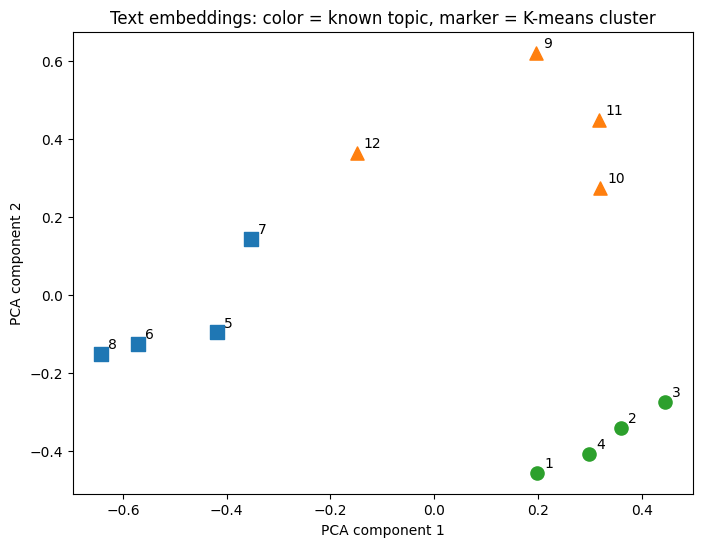

topic,finance,sports,technology
cluster,,,
0,0,4,0
1,0,0,4
2,4,0,0


In [ ]:
# PCA is used only for visualization; K-means still learns on the full 384-dimensional embeddings.
# Initialize PCA to compress the embeddings into two dimensions for plotting.
pca = PCA(n_components=2, random_state=26)
# Learn the PCA projection and transform each embedding into a 2D point.
points_2d = pca.fit_transform(news_embeddings)

# Create a plotting area large enough to display the point labels.
fig, ax = plt.subplots(figsize=(8, 6))
# Map the true topic to colors to compare it with the predicted cluster.
colors = {"sports": "tab:green", "technology": "tab:blue", "finance": "tab:orange"}
# Use different marker shapes to represent the three K-means clusters.
markers = ["o", "s", "^"]

# Iterate through each news item to draw its corresponding embedding point.
for index, item in enumerate(news_items):
    # Plot each point using the true topic color and the predicted cluster marker.
    ax.scatter(
        points_2d[index, 0],
        points_2d[index, 1],
        color=colors[item["topic"]],
        marker=markers[int(cluster_ids[index])],
        s=90,
    )
    # Add sequence numbers to align points on the chart with the data table.
    ax.annotate(str(index + 1), points_2d[index], xytext=(5, 4), textcoords="offset points")

ax.set_title("Text embeddings: color = known topic, marker = K-means cluster")
ax.set_xlabel("PCA component 1")
ax.set_ylabel("PCA component 2")
plt.show()

# Create a contingency table to count how many times each true topic appears in each cluster.
pd.crosstab(cluster_table["cluster"], cluster_table["topic"])

## 5. Text Classification

Sentence embeddings can be used as numerical features for a conventional supervised classifier.

The pipeline is:

1. encode labeled training texts
2. train a classifier such as logistic regression
3. encode new texts with the same Sentence Transformer
4. predict topic, sentiment, or user intent


In [ ]:
# Create labeled training data for three customer support intent types.
training_examples = [
    ("I was charged twice for the same subscription.", "billing"),
    ("Where can I download my invoice?", "billing"),
    ("How can I update my payment method?", "billing"),
    ("I need a refund for the last transaction.", "billing"),
    ("The amount on my bill is incorrect.", "billing"),
    ("When is my next payment due?", "billing"),
    ("The mobile application crashes when I open it.", "technical_support"),
    ("The website is loading very slowly.", "technical_support"),
    ("I cannot connect to the server.", "technical_support"),
    ("File upload fails with an error message.", "technical_support"),
    ("The screen freezes after the latest update.", "technical_support"),
    ("The page displays error code 503.", "technical_support"),
    ("How do I reset my account password?", "account_management"),
    ("I want to change the email address on my profile.", "account_management"),
    ("Please delete my account permanently.", "account_management"),
    ("How can I enable two-factor authentication?", "account_management"),
    ("I cannot sign in to my user account.", "account_management"),
    ("Where can I edit my profile information?", "account_management"),
]

# Create a test set with wording that differs from the training data.
test_examples = [
    ("The service billed my card two times.", "billing"),
    ("Please send me a receipt for my payment.", "billing"),
    ("The app closes immediately after launch.", "technical_support"),
    ("Why does the site keep showing a connection error?", "technical_support"),
    ("I need to use a different email for my account.", "account_management"),
    ("Help me create a new login password.", "account_management"),
]

# Embeddings are the input features; the intent labels are the target for supervised learning.
# Encode the full training sentences into an embedding feature matrix.
x_train = embed_texts([text for text, _ in training_examples])
# Split the training intent labels into a target array.
y_train = np.array([label for _, label in training_examples])
# Encode the test sentences using the same Sentence Transformer used for training.
x_test = embed_texts([text for text, _ in test_examples])
# Split the true labels of the test set to evaluate the model.
y_test = np.array([label for _, label in test_examples])

# Initialize Logistic Regression as the classifier on top of the embeddings.
intent_classifier = LogisticRegression(max_iter=1000, random_state=26)
# Train the classifier to learn the boundary between three intents in vector space.
intent_classifier.fit(x_train, y_train)

# Predict the intent for each test sentence.
predictions = intent_classifier.predict(x_test)
# Get class probabilities to illustrate the confidence level of the prediction.
probabilities = intent_classifier.predict_proba(x_test)

# Create a list to combine the text, true label, predicted label, and confidence.
prediction_rows = []
# Iterate through each test sample and fetch the prediction information at the same position.
for index, (text, expected) in enumerate(test_examples):
    # Save one result row containing all information needed for analysis.
    prediction_rows.append(
        {
            "text": text,
            "expected": expected,
            "predicted": predictions[index],
            "confidence": round(float(probabilities[index].max()), 3),
        }
    )

# Convert the prediction results into an easy-to-read table.
pd.DataFrame(prediction_rows)

,text,expected,predicted,confidence
0,The service billed my card two times.,billing,billing,0.546
1,Please send me a receipt for my payment.,billing,billing,0.634
2,The app closes immediately after launch.,technical_support,technical_support,0.528
3,Why does the site keep showing a connection er...,technical_support,technical_support,0.571
4,I need to use a different email for my account.,account_management,account_management,0.510
5,Help me create a new login password.,account_management,account_management,0.619


In [ ]:
# Compute the overall accuracy of predictions on the test set.
accuracy = accuracy_score(y_test, predictions)
# Compute precision, recall, and F1 for each class as a dictionary.
report = classification_report(y_test, predictions, output_dict=True, zero_division=0)

print("Accuracy:", round(float(accuracy), 3))
# Convert the report to a table, transpose it, and round it for readability.
display(pd.DataFrame(report).T.round(3))

# Sort the label list so the rows and columns of the confusion matrix have a stable order.
labels = sorted(set(y_train))
# Put the confusion matrix into a DataFrame with clear row and column labels.
pd.DataFrame(
    confusion_matrix(y_test, predictions, labels=labels),
    index=[f"actual: {label}" for label in labels],
    columns=[f"predicted: {label}" for label in labels],
)

Accuracy: 1.0


,precision,recall,f1-score,support
account_management,1.0,1.0,1.0,2.0
billing,1.0,1.0,1.0,2.0
technical_support,1.0,1.0,1.0,2.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,6.0
weighted avg,1.0,1.0,1.0,6.0


,predicted: account_management,predicted: billing,predicted: technical_support
actual: account_management,2,0,0
actual: billing,0,2,0
actual: technical_support,0,0,2


## 6. Recommendation System

Content-based recommendation uses semantic similarity between:

- a user profile and item descriptions
- one selected item and other items

Unlike collaborative filtering, this approach does not require behavior from many users. It can recommend new items as soon as their descriptions are available.


In [ ]:
# Define the course catalog with course code, title, and description.
courses = [
    {
        "id": "C01",
        "title": "Python Programming for Beginners",
        "description": "Learn Python syntax, functions, data structures, and practical programming skills.",
    },
    {
        "id": "C02",
        "title": "Data Analytics with Excel",
        "description": "Analyze business data with spreadsheets, pivot tables, dashboards, and formulas.",
    },
    {
        "id": "C03",
        "title": "Natural Language Processing with Transformers",
        "description": "Build systems for text embeddings, semantic search, classification, and question answering.",
    },
    {
        "id": "C04",
        "title": "Computer Vision with Deep Learning",
        "description": "Use neural networks for image classification, object detection, and visual applications.",
    },
    {
        "id": "C05",
        "title": "Digital Marketing Fundamentals",
        "description": "Plan campaigns, analyze audiences, manage social media, and improve online branding.",
    },
    {
        "id": "C06",
        "title": "Cloud Computing Essentials",
        "description": "Deploy scalable applications using cloud infrastructure, containers, and managed services.",
    },
    {
        "id": "C07",
        "title": "Machine Learning Foundations",
        "description": "Train predictive models for classification, regression, clustering, and recommendation.",
    },
]

# Concatenate title and description so the embedding better represents the course content.
course_embeddings = embed_texts([course["title"] + ". " + course["description"] for course in courses])


def recommend_for_profile(profile, top_k=4):
    """Recommend courses for a natural-language learner profile.

    Parameters:
        profile: Description of learner interests and goals.
        top_k: Number of courses to recommend.

    Returns:
        A DataFrame of ranked recommendations.
    """
    # Compare the learner profile with all courses and fetch the top_k results.
    results = rank_by_similarity(profile, courses, course_embeddings, top_k=top_k)
    # Return the recommendation table containing only the fields that need to be displayed.
    return pd.DataFrame(results)[["rank", "score", "id", "title", "description"]]


# Describe learner preferences in natural language instead of a fixed list of IDs.
learner_profile = "I want to learn natural language processing, sentence embeddings, semantic search, and question answering."
print("Learner profile:", learner_profile)
# Generate four suggestions whose descriptions are closest to the profile.
recommend_for_profile(learner_profile, top_k=4)

Learner profile: I want to learn natural language processing, sentence embeddings, semantic search, and question answering.


,rank,score,id,title,description
0,1,0.675452,C03,Natural Language Processing with Transformers,"Build systems for text embeddings, semantic se..."
1,2,0.505614,C01,Python Programming for Beginners,"Learn Python syntax, functions, data structure..."
2,3,0.324576,C04,Computer Vision with Deep Learning,"Use neural networks for image classification, ..."
3,4,0.291068,C07,Machine Learning Foundations,"Train predictive models for classification, re..."


In [ ]:
def similar_courses(course_id, top_k=3):
    """Recommend courses semantically similar to a selected course.

    Parameters:
        course_id: ID of the selected course.
        top_k: Number of related courses to return.

    Returns:
        A DataFrame of similar courses.
    """
    # Find the position of the course currently being viewed based on the course ID.
    selected_index = next(i for i, course in enumerate(courses) if course["id"] == course_id)

    # Compare item-to-item and remove the current course from the results.
    scores = course_embeddings @ course_embeddings[selected_index]
    # Rank in descending order, remove the current item itself, and keep the remaining top_k items.
    ranked_indices = [i for i in np.argsort(scores)[::-1] if i != selected_index][:top_k]
    # Create a list to store the ranked similar courses.
    rows = []
    # Iterate through the results and assign rank starting from 1.
    for rank, index in enumerate(ranked_indices, start=1):
        # Save the rank, similarity, and identifying information for the recommended course.
        rows.append(
            {
                "rank": rank,
                "score": float(scores[index]),
                "id": courses[int(index)]["id"],
                "title": courses[int(index)]["title"],
            }
        )
    # Return the item-to-item recommendation as a DataFrame.
    return pd.DataFrame(rows)


print("Selected course: C07 - Machine Learning Foundations")
# Find the three courses most similar to Machine Learning Foundations.
similar_courses("C07", top_k=3)

Selected course: C07 - Machine Learning Foundations


,rank,score,id,title
0,1,0.489307,C04,Computer Vision with Deep Learning
1,2,0.273009,C03,Natural Language Processing with Transformers
2,3,0.262673,C02,Data Analytics with Excel


## 7. Paraphrase Detection

Paraphrase detection asks whether two sentences express approximately the same meaning.

A simple system can:

1. embed both sentences
2. compute cosine similarity
3. compare the score with a threshold

The threshold should be calibrated on labeled examples from the target domain.


In [ ]:
# Create sentence pairs labeled True/False to illustrate paraphrase detection.
paraphrase_pairs = [
    (
        "How can I reset my password?",
        "What should I do to create a new account password?",
        True,
    ),
    (
        "The student submitted the assignment before the deadline.",
        "The student turned in the assignment before the due date.",
        True,
    ),
    (
        "The meeting starts at nine in the morning.",
        "The office closes at nine in the evening.",
        False,
    ),
    (
        "I need to pay my university fees.",
        "How can I submit my tuition payment?",
        True,
    ),
    (
        "A new software update fixed the security problem.",
        "The football team changed its defensive strategy.",
        False,
    ),
    (
        "Please cancel my course registration.",
        "I want to withdraw from the class.",
        True,
    ),
]


def detect_paraphrase(text_a, text_b, threshold=0.62):
    """Predict whether two texts are paraphrases.

    Parameters:
        text_a: First text.
        text_b: Second text.
        threshold: Minimum cosine similarity for a positive prediction.

    Returns:
        A tuple (is_paraphrase, score).
    """
    # Compute continuous similarity before applying the classification threshold.
    score = cosine_score(text_a, text_b)

    # The threshold converts continuous scores into True/False labels.
    return score >= threshold, score


# Create a list to store prediction results for every sentence pair.
paraphrase_rows = []
# Iterate through each sentence pair with its expected label.
for text_a, text_b, expected in paraphrase_pairs:
    # Convert similarity scores into paraphrase predictions using a threshold of 0.62.
    predicted, score = detect_paraphrase(text_a, text_b, threshold=0.62)
    # Save the text, true label, predicted label, and similarity score.
    paraphrase_rows.append(
        {
            "text A": text_a,
            "text B": text_b,
            "expected": expected,
            "predicted": predicted,
            "similarity": round(score, 3),
        }
    )

# Create a summary table to compare expected and predicted values.
paraphrase_table = pd.DataFrame(paraphrase_rows)
print("Accuracy on toy pairs:", round(float((paraphrase_table["expected"] == paraphrase_table["predicted"]).mean()), 3))
paraphrase_table

Accuracy on toy pairs: 1.0


,text A,text B,expected,predicted,similarity
0,How can I reset my password?,What should I do to create a new account passw...,True,True,0.622
1,The student submitted the assignment before th...,The student turned in the assignment before th...,True,True,0.855
2,The meeting starts at nine in the morning.,The office closes at nine in the evening.,False,False,0.508
3,I need to pay my university fees.,How can I submit my tuition payment?,True,True,0.700
4,A new software update fixed the security problem.,The football team changed its defensive strategy.,False,False,0.273
5,Please cancel my course registration.,I want to withdraw from the class.,True,True,0.673


## 8. Multilingual Semantic Search

A multilingual Sentence Transformer places semantically related sentences from different languages near one another.

This enables cross-language retrieval:

- a Vietnamese query can retrieve an English document
- an English query can retrieve a Vietnamese document
- the same index can contain several languages

No machine-translation step is required for this small retrieval pipeline.


In [ ]:
# Create a multilingual document index covering the same student service topics.
multilingual_documents = [
    {
        "id": "M01",
        "language": "English",
        "title": "Library borrowing",
        "text": "Students can borrow books from the university library with a student identification card.",
    },
    {
        "id": "M02",
        "language": "Vietnamese",
        "title": "Thanh toán học phí",
        "text": "Sinh viên có thể thanh toán học phí trực tuyến qua cổng thông tin của trường.",
    },
    {
        "id": "M03",
        "language": "French",
        "title": "Reinitialiser le mot de passe",
        "text": "Utilisez la page de securite du compte pour creer un nouveau mot de passe.",
    },
    {
        "id": "M04",
        "language": "Spanish",
        "title": "Inscripcion en cursos",
        "text": "Los estudiantes pueden matricularse en sus asignaturas mediante el portal academico.",
    },
    {
        "id": "M05",
        "language": "German",
        "title": "Sportvereine",
        "text": "Studierende koennen sich beim Studentenbuero fuer Sportvereine anmelden.",
    },
    {
        "id": "M06",
        "language": "English",
        "title": "Official transcript",
        "text": "Request an official academic transcript from the registrar's online service.",
    },
]

# The same model encodes all languages into one shared vector space.
multilingual_embeddings = embed_texts(
    [item["title"] + ". " + item["text"] for item in multilingual_documents]
)


def multilingual_search(query, top_k=3):
    """Search a multilingual document collection.

    Parameters:
        query: Query written in any supported language.
        top_k: Number of results to return.

    Returns:
        A DataFrame containing ranked multilingual results.
    """
    # Use the same ranking function because both queries and documents live in the same multilingual space.
    results = rank_by_similarity(
        query,
        multilingual_documents,
        multilingual_embeddings,
        top_k=top_k,
    )
    # Keep an additional language column to inspect cross-lingual retrieval.
    return pd.DataFrame(results)[["rank", "score", "id", "language", "title", "text"]]

In [ ]:
# Prepare queries in four languages to test cross-lingual retrieval capability.
multilingual_queries = [
    "Tôi có thể mượn sách ở thư viện bằng cách nào?", # Vietnamese query -> English document
    "How can I pay my tuition online?",               # English query -> Vietnamese document
    "Comment puis-je m'inscrire aux cours?",          # French query -> Spanish document
    "Olvide mi contrasena y necesito crear una nueva.", # Spanish query -> French document
]

# Run each query against the same multilingual embedding index.
for query in multilingual_queries:
    print("=" * 100)
    print("Query:", query)
    # Show the two closest results, even when they are in a different language from the query.
    display(multilingual_search(query, top_k=2))

Query: Tôi có thể mượn sách ở thư viện bằng cách nào?


,rank,score,id,language,title,text
0,1,0.710708,M01,English,Library borrowing,Students can borrow books from the university ...
1,2,0.224349,M06,English,Official transcript,Request an official academic transcript from t...


Query: How can I pay my tuition online?


,rank,score,id,language,title,text
0,1,0.711862,M02,Vietnamese,Thanh toán học phí,Sinh viên có thể thanh toán học phí trực tuyến...
1,2,0.397628,M04,Spanish,Inscripcion en cursos,Los estudiantes pueden matricularse en sus asi...


Query: Comment puis-je m'inscrire aux cours?


,rank,score,id,language,title,text
0,1,0.513807,M04,Spanish,Inscripcion en cursos,Los estudiantes pueden matricularse en sus asi...
1,2,0.479112,M05,German,Sportvereine,Studierende koennen sich beim Studentenbuero f...


Query: Olvide mi contrasena y necesito crear una nueva.


,rank,score,id,language,title,text
0,1,0.411870,M03,French,Reinitialiser le mot de passe,Utilisez la page de securite du compte pour cr...
1,2,0.079588,M05,German,Sportvereine,Studierende koennen sich beim Studentenbuero f...


## 9. Summary

This demo showed how one embedding model supports many applications:

- **text similarity** compares sentences, paragraphs, and documents
- **semantic search** retrieves meaning rather than exact keywords
- **retrieval chatbots** return approved answers from the nearest FAQ
- **clustering** discovers groups without labels
- **classification** uses embeddings as features for supervised learning
- **recommendation** matches profiles or items to descriptions
- **paraphrase detection** identifies different wording with similar meaning
- **multilingual search** connects queries and documents across languages


# Extra

## Experiment 1: Change FAQ Threshold

Let's observe how changing the `threshold` for the `answer_faq` function impacts the chatbot's ability to respond. A higher threshold means the chatbot requires a stronger semantic match to provide an answer, potentially leading to more refusals for less confident matches.

In [ ]:
# Using a higher threshold (e.g., 0.6) to make the chatbot more selective.

# Prepare three in-domain questions and one out-of-domain question for the FAQ knowledge base.
chat_questions = [
    "I cannot remember my login password.",
    "Who should I talk to about choosing next semester's classes?",
    "Where can I obtain an official transcript of my grades?",
    "What will the weather be on Mars tomorrow?",
]

print("--- Chatbot with HIGHER Threshold (0.6) ---")
for question in chat_questions:
    result = answer_faq(question, threshold=0.6)
    print("=" * 90)
    print("User:", result["user_question"])
    print("Matched FAQ:", result["matched_question"])
    print("Similarity:", round(result["score"], 3))
    print("Bot:", result["answer"])

print("\n--- Chatbot with ORIGINAL Threshold (0.43) ---")
# For comparison, let's also show the results with the original threshold
for question in chat_questions:
    result = answer_faq(question, threshold=0.43)
    print("=" * 90)
    print("User:", result["user_question"])
    print("Matched FAQ:", result["matched_question"])
    print("Similarity:", round(result["score"], 3))
    print("Bot:", result["answer"])

--- Chatbot with HIGHER Threshold (0.6) ---
User: I cannot remember my login password.
Matched FAQ: How can I reset my password?
Similarity: 0.781
Bot: Open Account Security, choose Reset Password, and verify the link sent to your email.
User: Who should I talk to about choosing next semester's classes?
Matched FAQ: How can I contact my academic advisor?
Similarity: 0.456
Bot: I do not have a sufficiently confident answer in the FAQ knowledge base.
User: Where can I obtain an official transcript of my grades?
Matched FAQ: How do I request an official transcript?
Similarity: 0.645
Bot: Submit a transcript request through the registrar's online service.
User: What will the weather be on Mars tomorrow?
Matched FAQ: How do I register for a course?
Similarity: 0.011
Bot: I do not have a sufficiently confident answer in the FAQ knowledge base.

--- Chatbot with ORIGINAL Threshold (0.43) ---
User: I cannot remember my login password.
Matched FAQ: How can I reset my password?
Similarity: 0.781

## Experiment 2: Add New Topics to Clustering Dataset and Increase Number of Clusters

Let's expand the `news_items` dataset with two new topics: "health" and "education". We will then increase the `n_clusters` parameter in `KMeans` to 5 (3 original topics + 2 new topics) to see if the model can correctly group these new categories.

Expanded Cluster Table:


,cluster,text,topic
16,0,The university unveiled a new curriculum for c...,education
12,0,Scientists discovered a new treatment for a ra...,health
13,0,Public health officials issued a warning about...,health
15,0,A major hospital announced plans for a new can...,health
4,0,A software company released a faster artificia...,technology
5,0,Researchers introduced a new model for underst...,technology
6,0,The mobile application added stronger privacy ...,technology
7,0,Cloud providers announced new tools for traini...,technology
0,1,The football club signed a new striker before ...,sports
3,1,The coach changed the defensive strategy for t...,sports


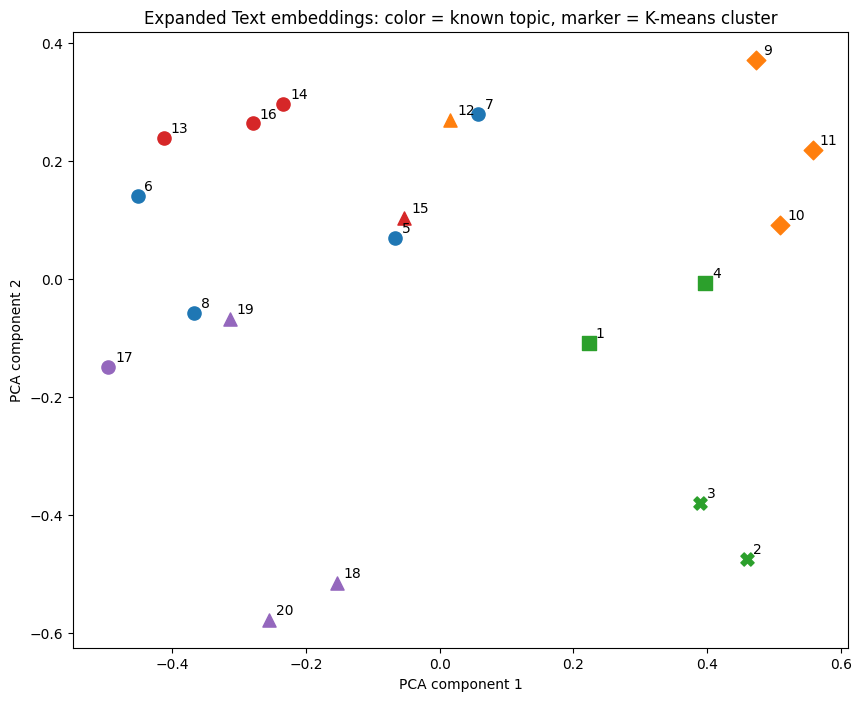


Cross-tabulation of Expanded Clusters:


topic,education,finance,health,sports,technology
cluster,,,,,
0,1,0,3,0,4
1,0,0,0,2,0
2,3,1,1,0,0
3,0,3,0,0,0
4,0,0,0,2,0


In [ ]:
# Adding two new topics ('health' and 'education') to the existing news_items.
# The original news_items will be extended.

expanded_news_items = [
    # Original sports items
    {"text": "The football club signed a new striker before the national tournament.", "topic": "sports"},
    {"text": "The basketball team won after scoring in the final seconds.", "topic": "sports"},
    {"text": "The tennis player advanced to the championship match.", "topic": "sports"},
    {"text": "The coach changed the defensive strategy for the next game.", "topic": "sports"},
    # Original technology items
    {"text": "A software company released a faster artificial intelligence processor.", "topic": "technology"},
    {"text": "Researchers introduced a new model for understanding images and text.", "topic": "technology"},
    {"text": "The mobile application added stronger privacy and security controls.", "topic": "technology"},
    {"text": "Cloud providers announced new tools for training machine learning systems.", "topic": "technology"},
    # Original finance items
    {"text": "The central bank increased interest rates to control inflation.", "topic": "finance"},
    {"text": "Shares rose after the company reported higher quarterly profits.", "topic": "finance"},
    {"text": "Investors moved money into bonds during a volatile trading session.", "topic": "finance"},
    {"text": "The government published its economic growth forecast for next year.", "topic": "finance"},
    # New health items
    {"text": "Scientists discovered a new treatment for a rare disease.", "topic": "health"},
    {"text": "Public health officials issued a warning about a new virus strain.", "topic": "health"},
    {"text": "New dietary guidelines recommend more plant-based foods.", "topic": "health"},
    {"text": "A major hospital announced plans for a new cancer research center.", "topic": "health"},
    # New education items
    {"text": "The university unveiled a new curriculum for computer science students.", "topic": "education"},
    {"text": "Online learning platforms reported record enrollment numbers this semester.", "topic": "education"},
    {"text": "A national initiative aims to improve STEM education in schools.", "topic": "education"},
    {"text": "Scholarships are now available for students pursuing vocational training.", "topic": "education"},
]

# Embed the expanded news items.
expanded_news_embeddings = embed_texts([item["text"] for item in expanded_news_items])

# Initialize K-means with 5 clusters (3 original + 2 new topics).
kmeans_expanded = KMeans(n_clusters=5, random_state=26, n_init=20)
# Fit K-means on the new embeddings.
cluster_ids_expanded = kmeans_expanded.fit_predict(expanded_news_embeddings)

# Create a DataFrame for the expanded cluster results.
cluster_table_expanded = pd.DataFrame(expanded_news_items)
cluster_table_expanded.insert(0, "cluster", cluster_ids_expanded)

print("Expanded Cluster Table:")
display(cluster_table_expanded.sort_values(["cluster", "topic"]))

# Visualize the expanded clusters using PCA.
pca_expanded = PCA(n_components=2, random_state=26)
points_2d_expanded = pca_expanded.fit_transform(expanded_news_embeddings)

fig, ax = plt.subplots(figsize=(10, 8))

# Updated colors and markers for 5 topics/clusters
colors_expanded = {
    "sports": "tab:green",
    "technology": "tab:blue",
    "finance": "tab:orange",
    "health": "tab:red",
    "education": "tab:purple",
}
markers_expanded = ["o", "s", "^", "D", "X"]

for index, item in enumerate(expanded_news_items):
    ax.scatter(
        points_2d_expanded[index, 0],
        points_2d_expanded[index, 1],
        color=colors_expanded[item["topic"]],
        marker=markers_expanded[int(cluster_ids_expanded[index])],
        s=90,
    )
    ax.annotate(str(index + 1), points_2d_expanded[index], xytext=(5, 4), textcoords="offset points")

ax.set_title("Expanded Text embeddings: color = known topic, marker = K-means cluster")
ax.set_xlabel("PCA component 1")
ax.set_ylabel("PCA component 2")
plt.show()

print("\nCross-tabulation of Expanded Clusters:")
display(pd.crosstab(cluster_table_expanded["cluster"], cluster_table_expanded["topic"]))

## Experiment 3: Add More Labeled Examples to the Intent Classifier

We will expand the training and test datasets for the intent classifier with more examples for existing categories (`billing`, `technical_support`, `account_management`). This will help demonstrate how more data can refine the model's ability to classify user intent. We will then re-train and evaluate the `LogisticRegression` model.

In [ ]:
# Expanded training examples
expanded_training_examples = [
    ("I was charged twice for the same subscription.", "billing"),
    ("Where can I download my invoice?", "billing"),
    ("How can I update my payment method?", "billing"),
    ("I need a refund for the last transaction.", "billing"),
    ("The amount on my bill is incorrect.", "billing"),
    ("When is my next payment due?", "billing"),
    ("My last payment failed, what should I do?", "billing"),
    ("Can I get a receipt for my payment?", "billing"),
    ("My billing address is wrong.", "billing"),
    ("The mobile application crashes when I open it.", "technical_support"),
    ("The website is loading very slowly.", "technical_support"),
    ("I cannot connect to the server.", "technical_support"),
    ("File upload fails with an error message.", "technical_support"),
    ("The screen freezes after the latest update.", "technical_support"),
    ("The page displays error code 503.", "technical_support"),
    ("My internet connection is unstable.", "technical_support"),
    ("The software is not installing correctly.", "technical_support"),
    ("I keep getting error messages.", "technical_support"),
    ("How do I reset my account password?", "account_management"),
    ("I want to change the email address on my profile.", "account_management"),
    ("Please delete my account permanently.", "account_management"),
    ("How can I enable two-factor authentication?", "account_management"),
    ("I cannot sign in to my user account.", "account_management"),
    ("Where can I edit my profile information?", "account_management"),
    ("I want to change my username.", "account_management"),
    ("How do I update my personal details?", "account_management"),
    ("My account is locked.", "account_management"),
]

# Expanded test examples
expanded_test_examples = [
    ("I received two charges for one service.", "billing"),
    ("Where is my payment receipt?", "billing"),
    ("The app shuts down unexpectedly.", "technical_support"),
    ("The site is very slow to respond.", "technical_support"),
    ("I need to change the email linked to my profile.", "account_management"),
    ("I forgot my password and need to set a new one.", "account_management"),
    ("My credit card was charged twice.", "billing"),
    ("The software is freezing.", "technical_support"),
    ("I want to close my account.", "account_management"),
]

x_train_expanded = embed_texts([text for text, _ in expanded_training_examples])
y_train_expanded = np.array([label for _, label in expanded_training_examples])
x_test_expanded = embed_texts([text for text, _ in expanded_test_examples])
y_test_expanded = np.array([label for _, label in expanded_test_examples])

intent_classifier_expanded = LogisticRegression(max_iter=1000, random_state=26)
intent_classifier_expanded.fit(x_train_expanded, y_train_expanded)

predictions_expanded = intent_classifier_expanded.predict(x_test_expanded)
probabilities_expanded = intent_classifier_expanded.predict_proba(x_test_expanded)

prediction_rows_expanded = []
for index, (text, expected) in enumerate(expanded_test_examples):
    prediction_rows_expanded.append(
        {
            "text": text,
            "expected": expected,
            "predicted": predictions_expanded[index],
            "confidence": round(float(probabilities_expanded[index].max()), 3),
        }
    )

print("--- Experiment 3: Expanded Intent Classifier Results ---")
display(pd.DataFrame(prediction_rows_expanded))

accuracy_expanded = accuracy_score(y_test_expanded, predictions_expanded)
report_expanded = classification_report(y_test_expanded, predictions_expanded, output_dict=True, zero_division=0)

print("\nAccuracy (Expanded):", round(float(accuracy_expanded), 3))
display(pd.DataFrame(report_expanded).T.round(3))

labels_expanded = sorted(set(y_train_expanded))
display(
    pd.DataFrame(
        confusion_matrix(y_test_expanded, predictions_expanded, labels=labels_expanded),
        index=[f"actual: {label}" for label in labels_expanded],
        columns=[f"predicted: {label}" for label in labels_expanded],
    )
)

--- Experiment 3: Expanded Intent Classifier Results ---


,text,expected,predicted,confidence
0,I received two charges for one service.,billing,billing,0.586
1,Where is my payment receipt?,billing,billing,0.724
2,The app shuts down unexpectedly.,technical_support,technical_support,0.620
3,The site is very slow to respond.,technical_support,technical_support,0.624
4,I need to change the email linked to my profile.,account_management,account_management,0.652
5,I forgot my password and need to set a new one.,account_management,account_management,0.632
6,My credit card was charged twice.,billing,billing,0.619
7,The software is freezing.,technical_support,technical_support,0.623
8,I want to close my account.,account_management,account_management,0.522



Accuracy (Expanded): 1.0


,precision,recall,f1-score,support
account_management,1.0,1.0,1.0,3.0
billing,1.0,1.0,1.0,3.0
technical_support,1.0,1.0,1.0,3.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,9.0
weighted avg,1.0,1.0,1.0,9.0


,predicted: account_management,predicted: billing,predicted: technical_support
actual: account_management,3,0,0
actual: billing,0,3,0
actual: technical_support,0,0,3


## Experiment 4: Calibrate the Paraphrase Threshold Using a Validation Set

This experiment focuses on finding a suitable threshold for paraphrase detection. We'll use a new validation set with various paraphrase and non-paraphrase pairs, calculate their similarities, and then test different cosine similarity thresholds to see which one yields the highest accuracy.

In [ ]:
# A new validation set for paraphrase detection with varying similarities.
validation_paraphrase_pairs = [
    ("How can I change my password?", "I want to reset my login details.", True),  # High similarity
    ("The cat sat on the mat.", "A feline was perched on the rug.", True),         # High similarity
    ("Where is the nearest coffee shop?", "Can you tell me where to find a cafe?", True), # Moderate similarity
    ("The car is red.", "The vehicle is blue.", False),                             # Low similarity
    ("I love to read books.", "I enjoy gardening.", False),                         # Very low similarity
    ("He bought a new phone.", "He purchased a new smartphone.", True),             # High similarity
    ("The weather is bad today.", "The rain is falling heavily.", True),            # Moderate similarity (implied)
    ("The store is open now.", "The shop is currently closed.", False),             # Opposite meaning
    ("I need help with my homework.", "Can you assist me with my assignments?", True), # High similarity
    ("The dog barked loudly.", "The cat purred softly.", False),                    # Different subjects/actions
]

# Calculate similarities for the validation set.
validation_scores = []
for text_a, text_b, _ in validation_paraphrase_pairs:
    validation_scores.append(cosine_score(text_a, text_b))

# Evaluate different thresholds.
threshold_results = []
test_thresholds = np.arange(0.5, 0.8, 0.05) # Test thresholds from 0.5 to 0.75

for threshold in test_thresholds:
    correct_predictions = 0
    total_predictions = len(validation_paraphrase_pairs)

    for i, (text_a, text_b, expected) in enumerate(validation_paraphrase_pairs):
        predicted = validation_scores[i] >= threshold
        if predicted == expected:
            correct_predictions += 1

    accuracy = correct_predictions / total_predictions
    threshold_results.append({"Threshold": round(threshold, 2), "Accuracy": round(accuracy, 3)})

print("\n--- Experiment 4: Paraphrase Threshold Calibration ---")
display(pd.DataFrame(threshold_results))

# Display actual scores and expected vs predicted for a chosen threshold (e.g., 0.65)
optimal_threshold = 0.65 # Choose one for detailed display
paraphrase_validation_rows = []
for i, (text_a, text_b, expected) in enumerate(validation_paraphrase_pairs):
    predicted = validation_scores[i] >= optimal_threshold
    paraphrase_validation_rows.append({
        "text A": text_a,
        "text B": text_b,
        "expected": expected,
        "predicted": predicted,
        "similarity": round(validation_scores[i], 3)
    })
print(f"\nDetailed results with chosen threshold ({optimal_threshold}):")
display(pd.DataFrame(paraphrase_validation_rows))


--- Experiment 4: Paraphrase Threshold Calibration ---


,Threshold,Accuracy
0,0.50,0.9
1,0.55,1.0
2,0.60,0.9
3,0.65,0.7
4,0.70,0.6
5,0.75,0.6
6,0.80,0.5



Detailed results with chosen threshold (0.65):


,text A,text B,expected,predicted,similarity
0,How can I change my password?,I want to reset my login details.,True,False,0.649
1,The cat sat on the mat.,A feline was perched on the rug.,True,True,0.674
2,Where is the nearest coffee shop?,Can you tell me where to find a cafe?,True,True,0.768
3,The car is red.,The vehicle is blue.,False,False,0.281
4,I love to read books.,I enjoy gardening.,False,False,0.396
5,He bought a new phone.,He purchased a new smartphone.,True,True,0.939
6,The weather is bad today.,The rain is falling heavily.,True,False,0.563
7,The store is open now.,The shop is currently closed.,False,False,0.533
8,I need help with my homework.,Can you assist me with my assignments?,True,False,0.611
9,The dog barked loudly.,The cat purred softly.,False,False,0.235


## Experiment 5: Add Vietnamese Text with Accents to the Multilingual Collection and Compare Results

We will expand the multilingual document collection to include more Vietnamese text, specifically with accents, and then perform semantic search with new queries (including an accented Vietnamese query) to observe how the model handles these linguistic nuances in cross-language retrieval.

In [ ]:
# Expanded multilingual documents with accented Vietnamese text
expanded_multilingual_documents_exp5 = [
    {
        "id": "M01",
        "language": "English",
        "title": "Library borrowing",
        "text": "Students can borrow books from the university library with a student identification card.",
    },
    {
        "id": "M02",
        "language": "Vietnamese",
        "title": "Thanh toán học phí",
        "text": "Sinh viên có thể thanh toán học phí trực tuyến qua cổng thông tin của trường.",
    },
    {
        "id": "M03",
        "language": "French",
        "title": "Reinitialiser le mot de passe",
        "text": "Utilisez la page de securite du compte pour creer un nouveau mot de passe.",
    },
    {
        "id": "M04",
        "language": "Spanish",
        "title": "Inscripcion en cursos",
        "text": "Los estudiantes pueden matricularse en sus asignaturas mediante el portal academico.",
    },
    {
        "id": "M05",
        "language": "German",
        "title": "Sportvereine",
        "text": "Studierende koennen sich beim Studentenbuero fuer Sportvereine anmelden.",
    },
    {
        "id": "M06",
        "language": "English",
        "title": "Official transcript",
        "text": "Request an official academic transcript from the registrar's online service.",
    },
    # New Vietnamese document with accents
    {
        "id": "M07",
        "language": "Vietnamese",
        "title": "Yêu cầu bảng điểm",
        "text": "Sinh viên có thể yêu cầu bảng điểm chính thức từ dịch vụ trực tuyến của phòng đào tạo.",
    },
    # New English document for more diversity
    {
        "id": "M08",
        "language": "English",
        "title": "Student dormitories",
        "text": "Information about applying for student accommodation and dormitories is available on the housing portal.",
    },
]

# Re-embed the expanded multilingual documents.
expanded_multilingual_embeddings_exp5 = embed_texts(
    [item["title"] + ". " + item["text"] for item in expanded_multilingual_documents_exp5]
)

def expanded_multilingual_search(query, top_k=3):
    """Search an expanded multilingual document collection.

    Parameters:
        query: Query written in any supported language.
        top_k: Number of results to return.

    Returns:
        A DataFrame containing ranked multilingual results.
    """
    results = rank_by_similarity(
        query,
        expanded_multilingual_documents_exp5,
        expanded_multilingual_embeddings_exp5,
        top_k=top_k,
    )
    return pd.DataFrame(results)[["rank", "score", "id", "language", "title", "text"]]

# Expanded multilingual queries including accented Vietnamese
expanded_multilingual_queries_exp5 = [
    "Tôi có thể mượn sách ở thư viện bằng cách nào?",             # Vietnamese query -> English document (Library)
    "How can I pay my tuition online?",                           # English query -> Vietnamese document (Tuition)
    "Comment puis-je m'inscrire aux cours?",                      # French query -> Spanish document (Courses)
    "Olvide mi contrasena y necesito crear una nueva.",           # Spanish query -> French document (Password)
    "Tôi muốn lấy bảng điểm chính thức của mình.",               # Accented Vietnamese query -> Accented Vietnamese document (Transcript)
    "Where can I find information about student housing?",        # English query -> English document (Dormitories)
]

print("\n--- Experiment 5: Multilingual Search with Accented Vietnamese ---")
for query in expanded_multilingual_queries_exp5:
    print("=" * 100)
    print("Query:", query)
    display(expanded_multilingual_search(query, top_k=2))


--- Experiment 5: Multilingual Search with Accented Vietnamese ---
Query: Tôi có thể mượn sách ở thư viện bằng cách nào?


,rank,score,id,language,title,text
0,1,0.710708,M01,English,Library borrowing,Students can borrow books from the university ...
1,2,0.224349,M06,English,Official transcript,Request an official academic transcript from t...


Query: How can I pay my tuition online?


,rank,score,id,language,title,text
0,1,0.711862,M02,Vietnamese,Thanh toán học phí,Sinh viên có thể thanh toán học phí trực tuyến...
1,2,0.397628,M04,Spanish,Inscripcion en cursos,Los estudiantes pueden matricularse en sus asi...


Query: Comment puis-je m'inscrire aux cours?


...

,rank,score,id,language,title,text
0,1,0.411870,M03,French,Reinitialiser le mot de passe,Utilisez la page de securite du compte pour cr...
1,2,0.089542,M07,Vietnamese,Yêu cầu bảng điểm,Sinh viên có thể yêu cầu bảng điểm chính thức ...


Query: Tôi muốn lấy bảng điểm chính thức của mình.


,rank,score,id,language,title,text
0,1,0.490141,M07,Vietnamese,Yêu cầu bảng điểm,Sinh viên có thể yêu cầu bảng điểm chính thức ...
1,2,0.368522,M04,Spanish,Inscripcion en cursos,Los estudiantes pueden matricularse en sus asi...


Query: Where can I find information about student housing?


,rank,score,id,language,title,text
0,1,0.790497,M08,English,Student dormitories,Information about applying for student accommo...
1,2,0.400698,M02,Vietnamese,Thanh toán học phí,Sinh viên có thể thanh toán học phí trực tuyến...
